In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
from abc import ABC, abstractmethod
import time

In [ ]:
# verifica GPU dispoível no ambiente
!which nvidia-smi

In [ ]:
# informa GPU disponível no ambiente
!/opt/bin/nvidia-smi

/bin/bash: line 1: /opt/bin/nvidia-smi: No such file or directory


In [ ]:
try:
    import cupy as cp
    GPU_DISPONIVEL = cp.cuda.runtime.getDeviceCount() > 0
    print(f"GPU disponível: {GPU_DISPONIVEL}")
except ImportError:
    GPU_DISPONIVEL = False
    cp = None

In [ ]:
class GridWorldDynamicBuilder:
    """
    Construtor genérico de dinâmica P[s][a] para GridWorlds.

    ─── CONVENÇÃO (Padrão A — cartesiano) ───────────────────────
        (x, y) com y crescendo PARA CIMA.
        (0, 0) = canto INFERIOR esquerdo.
        y = 0 é a LINHA DE BAIXO; y = nlin-1 é a LINHA DE CIMA.

    ─── ESTADO s ────────────────────────────────────────────────
        s = row * ncol + x, com row = 0 sendo a LINHA DO TOPO.
        Portanto:
            s = 0           -> (x=0, y=nlin-1)  -> canto SUP. ESQ.
            s = nlin*ncol-1 -> (x=ncol-1, y=0)  -> canto INF. DIR.

    ─── AÇÕES (Padrão A) ────────────────────────────────────────
        0: Cima    -> dy = +1
        1: Direita -> dx = +1
        2: Baixo   -> dy = -1
        3: Esquerda-> dx = -1
    """
    ACOES = {
        0: (0, +1),   # Cima
        1: (1, 0),    # Direita
        2: (0, -1),   # Baixo
        3: (-1, 0),   # Esquerda
    }

    def __init__(self, nlin: int = 5, ncol: int = 5,
                 rec_padrao: float = 0.0, rec_parede: float = -1.0):
        self.nlin = nlin
        self.ncol = ncol
        self.n_states = nlin * ncol
        self.n_actions = len(self.ACOES)

        self.saltos = {}
        self.recompensas_padrao = {}
        self.terminais = set()
        self.obstaculos = set()
        self.recompensa_passo_padrao = rec_padrao
        self.recompensa_parede = rec_parede

    # ---------- Conversões (Padrão A) ----------
    def pos_to_state(self, x: int, y: int) -> int:
        """(x, y) com y crescendo para cima -> índice s."""
        row = (self.nlin - 1) - y
        return row * self.ncol + x

    def state_to_pos(self, s: int) -> tuple:
        """índice s -> (x, y) com y crescendo para cima."""
        row = s // self.ncol
        col = s % self.ncol
        y = (self.nlin - 1) - row
        return col, y

    # ---------- Saltos ----------
    def adicionar_salto(self, s_orig: int, s_dest: int, reward: float):
        self.saltos[s_orig] = (s_dest, reward)

    def adicionar_salto_pos(self, orig_x, orig_y, dest_x, dest_y, reward):
        self.adicionar_salto(
            self.pos_to_state(orig_x, orig_y),
            self.pos_to_state(dest_x, dest_y),
            reward,
        )

    # ---------- Terminais / obstáculos ----------
    def adicionar_terminal(self, s: int):
        self.terminais.add(s)

    def adicionar_obstaculo(self, s: int):
        self.obstaculos.add(s)

    # ---------- Build ----------
    def build_P(self) -> dict:
        P = {s: {a: [] for a in range(self.n_actions)}
             for s in range(self.n_states)}

        for s in range(self.n_states):
            x, y = self.state_to_pos(s)

            if s in self.terminais:
                for a in range(self.n_actions):
                    P[s][a] = [(1.0, s, 0.0, True)]
                continue

            if s in self.saltos:
                next_s, reward = self.saltos[s]
                for a in range(self.n_actions):
                    P[s][a] = [(1.0, next_s, reward, False)]
                continue

            for a, (dx, dy) in self.ACOES.items():
                nx, ny = x + dx, y + dy

                if nx < 0 or nx >= self.ncol or ny < 0 or ny >= self.nlin:
                    next_s = s
                    reward = self.recompensa_parede
                elif self.pos_to_state(nx, ny) in self.obstaculos:
                    next_s = s
                    reward = self.recompensa_parede
                else:
                    next_s = self.pos_to_state(nx, ny)
                    reward = self.recompensas_padrao.get(
                        next_s, self.recompensa_passo_padrao)

                done = next_s in self.terminais
                P[s][a] = [(1.0, next_s, reward, done)]

        return P

In [ ]:
# ============================================================
# Exemplo 3.5 / 3.8 — Padrão A
#
# Reindexação dos saltos do MDP original (Padrão B) para Padrão A.
# Fórmula: s_novo = (nlin-1 - linha_antiga) * ncol + coluna_antiga
#
#   A  (s=1  em Padrão B) -> s=21 em Padrão A (5x5)
#   A' (s=21 em Padrão B) -> s=1  em Padrão A
#   B  (s=3  em Padrão B) -> s=23 em Padrão A
#   B' (s=13 em Padrão B) -> s=11 em Padrão A
# ============================================================
builder = GridWorldDynamicBuilder(nlin=5, ncol=5)

builder.adicionar_salto(s_orig=1, s_dest=21, reward=10.0)
builder.adicionar_salto(s_orig=3, s_dest=13, reward=5.0)

P_exemplo35 = builder.build_P()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize


class VisualizadorResultadoIndependente:
    """
    Visualizador de V e pi no Padrão A:
        s -> (x, y) com y crescendo PARA CIMA.
        s = 0 -> (0, nlin-1) -> canto SUPERIOR esquerdo.
    """

    # Ações no Padrão A
    ACOES_DXY = {
        0: (0, +1),   # Cima  -> +y
        1: (+1, 0),   # Direita
        2: (0, -1),   # Baixo -> -y
        3: (-1, 0),   # Esquerda
    }

    def __init__(self, P_dinamica, nlin=5, ncol=5, n_actions=4,
                 estado_inicial=0, estados_terminais=None,
                 cmap_valores="viridis"):
        self.P = P_dinamica
        self.nlin = nlin
        self.ncol = ncol
        self.num_estados = nlin * ncol
        self.n_actions = n_actions
        self.estado_inicial = estado_inicial
        self.estados_terminais = set(estados_terminais) \
            if estados_terminais else set()
        self.cmap = plt.get_cmap(cmap_valores)

    def _para_numpy(self, x, dtype=None):
        if x is None:
            return None
        if hasattr(x, "get") and not isinstance(x, np.ndarray):
            x = x.get()
        elif hasattr(x, "cpu") and not isinstance(x, np.ndarray):
            x = x.cpu().numpy()
        return np.asarray(x, dtype=dtype)

    def _state_to_coords(self, s):
        """s -> (x, y) com y crescendo PARA CIMA."""
        row = s // self.ncol
        col = s % self.ncol
        y = (self.nlin - 1) - row
        return col, y

    def _is_terminal(self, s):
        return s in self.estados_terminais

    def _extrair_acao(self, politica, s):
        if politica.ndim == 1:
            return int(politica[s])
        return int(np.argmax(politica[s]))

    def _transicao_mais_provavel(self, s, a):
        return max(self.P[s][a], key=lambda t: t[0])[1]

    def _simular_politica(self, politica, s0=None, max_passos=500):
        if s0 is None:
            s0 = self.estado_inicial
        s = s0
        caminho = [s]
        for _ in range(max_passos):
            a = self._extrair_acao(politica, s)
            s_prox = self._transicao_mais_provavel(s, a)
            if self._is_terminal(s) or s_prox == s:
                break
            caminho.append(s_prox)
            if self._is_terminal(s_prox):
                break
            s = s_prox
        return caminho

    def desenhar(self, V, politica, ax=None,
                 mostrar_valores=True, mostrar_setas=True,
                 mostrar_rastro=True, mostrar_estados=True,
                 mostrar_colorbar=True, titulo=None,
                 mostrar_todas_acoes=False):

        V = self._para_numpy(V, dtype=float)
        politica = self._para_numpy(politica)

        fig = None
        if ax is None:
            fig, ax = plt.subplots(figsize=(self.ncol, self.nlin))
        else:
            fig = ax.figure

        vmin, vmax = float(V.min()), float(V.max())
        norm = Normalize(vmin=vmin, vmax=vmax)
        vnorm = np.zeros_like(V) if abs(vmax - vmin) < 1e-12 else norm(V)

        caminho = set(self._simular_politica(politica)) \
            if mostrar_rastro and not mostrar_todas_acoes else set()

        for s in range(self.num_estados):
            x, y = self._state_to_coords(s)
            terminal = self._is_terminal(s)
            face = "#dddddd" if terminal else self.cmap(vnorm[s])

            ax.add_patch(Rectangle((x, y), 1, 1, facecolor=face,
                                   edgecolor="gray", linewidth=0.8, alpha=0.9))
            if s == self.estado_inicial:
                ax.add_patch(Rectangle((x, y), 1, 1, facecolor="none",
                                       edgecolor="orange", linewidth=3))
            if terminal:
                ax.add_patch(Rectangle((x, y), 1, 1, facecolor="none",
                                       edgecolor="green", linewidth=2))

            if mostrar_estados:
                ax.text(x + 0.08, y + 0.92, str(s),
                        ha="left", va="top", fontsize=7,
                        color="black", alpha=0.6)
            if mostrar_valores:
                ax.text(x + 0.5, y + 0.5, f"{V[s]:.2f}",
                        ha="center", va="center", fontsize=9,
                        color="white", fontweight="bold")

        if mostrar_setas:
            for s in range(self.num_estados):
                if self._is_terminal(s):
                    continue
                x, y = self._state_to_coords(s)

                if mostrar_todas_acoes:
                    for a in range(self.n_actions):
                        dx, dy = self.ACOES_DXY[a]
                        ax.arrow(x + 0.5, y + 0.5, dx*0.20, dy*0.20,
                                 head_width=0.09, head_length=0.07,
                                 length_includes_head=True,
                                 color="lightgray", linewidth=1.0, alpha=0.7)
                else:
                    a = self._extrair_acao(politica, s)
                    dx, dy = self.ACOES_DXY[a]
                    cor = "red" if s in caminho else "blue"
                    lw = 2.2 if s in caminho else 1.2
                    ax.arrow(x + 0.5, y + 0.5, dx*0.28, dy*0.28,
                             head_width=0.12, head_length=0.10,
                             length_includes_head=True,
                             color=cor, linewidth=lw, alpha=0.95)

        # Limites dos eixos: y=0 embaixo, y=nlin-1 em cima (Padrão A)
        ax.set_xlim(0, self.ncol)
        ax.set_ylim(0, self.nlin)          # <-- NÃO inverter
        ax.set_aspect("equal")
        ax.set_xticks([]); ax.set_yticks([])

        if titulo:
            ax.set_title(titulo, fontsize=12, fontweight="bold")

        if mostrar_colorbar and fig is not None:
            sm = ScalarMappable(cmap=self.cmap, norm=norm)
            sm.set_array([])
            cbar = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.04)
            cbar.ax.tick_params(labelsize=8)

        return ax

    def comparar(self, resultados, salvar=None, figsize_por_painel=4.0,
                 mostrar_todas_acoes_glob=False):
        n = len(resultados)
        fig, axes = plt.subplots(1, n,
                                 figsize=(figsize_por_painel*n,
                                          figsize_por_painel),
                                 squeeze=False)
        for ax, (nome, (V, pi)) in zip(axes[0], resultados.items()):
            self.desenhar(V, pi, ax=ax, titulo=nome,
                          mostrar_todas_acoes=mostrar_todas_acoes_glob)
        plt.tight_layout()
        if salvar:
            plt.savefig(salvar, dpi=150, bbox_inches="tight")
        return fig

In [ ]:
# =====================================================================
# 1. CLASSE BASE ABSTRATA
# =====================================================================
class BasePolicyEvaluator(ABC):
    """
    Interface base para avaliadores de política de um MDP.
    """
    def __init__(self, n_states: int, n_actions: int, gamma: float = 0.9, theta: float = 1e-6):
        self.n_states = n_states
        self.n_actions = n_actions
        self.gamma = gamma
        self.theta = theta

    @abstractmethod
    def evaluate(self, policy: np.ndarray) -> np.ndarray:
        """
        Calcula e retorna o vetor de valor V_pi para uma dada matriz de política pi(a|s).
        `policy`: ndarray de dimensão (n_states, n_actions)
        """
        pass

In [ ]:
# =====================================================================
# 2. IMPLEMENTAÇÃO ITERATIVA PURA (Laços sobre o P do Gymnasium)
# =====================================================================
class IterativePolicyEvaluator(BasePolicyEvaluator):
    """
    Avaliação iterativa ponto-a-ponto varrendo o dicionário P[s][a] do Gymnasium.
    """
    def __init__(self, P: dict, n_states: int, n_actions: int, gamma: float = 0.9, theta: float = 1e-6):
        super().__init__(n_states, n_actions, gamma, theta)
        self.P = P  # Dicionário Gymnasium P[s][a]

    def evaluate(self, policy: np.ndarray) -> np.ndarray:
        V = np.zeros(self.n_states)

        while True:
            delta = 0.0
            V_old = V.copy()

            for s in range(self.n_states):
                v_new = 0.0
                for a in range(self.n_actions):
                    action_prob = policy[s, a]
                    if action_prob == 0:
                        continue

                    for prob, next_s, reward, done in self.P[s][a]:
                        term = 0.0 if done else V_old[next_s]
                        v_new += action_prob * prob * (reward + self.gamma * term)

                V[s] = v_new
                delta = max(delta, abs(V_old[s] - V[s]))

            if delta < self.theta:
                break

        return V

In [ ]:
# =====================================================================
# 3. IMPLEMENTAÇÃO VETORIZADA (NumPy / CuPy)
# =====================================================================
class VectorizedPolicyEvaluator(BasePolicyEvaluator):
    """
    Avaliação iterativa vetorizada utilizando a notação vetorial V = R_pi + gamma * P_pi @ V.
    Compatível com NumPy e CuPy (basta injetar o módulo xp correspondente).
    """
    def __init__(self, P: dict, n_states: int, n_actions: int, gamma: float = 0.9, theta: float = 1e-6, xp=np):
        super().__init__(n_states, n_actions, gamma, theta)
        self.xp = xp  # Módulo de computação (numpy ou cupy)

        # Constrói o Tensor de Transição T (S, A, S) e a Matriz de Recompensa R (S, A)
        # conforme detalhado na Seção 3.1 da sua minuta
        self.T = self.xp.zeros((n_states, n_actions, n_states))
        self.R = self.xp.zeros((n_states, n_actions))
        self._build_tensors(P)

    def _build_tensors(self, P: dict):
        """Converte a estrutura P[s][a] do Gymnasium em tensores densos para vetorização."""
        for s in range(self.n_states):
            for a in range(self.n_actions):
                for prob, next_s, reward, done in P[s][a]:
                    self.R[s, a] += prob * reward
                    if not done:
                        self.T[s, a, next_s] += prob

    def evaluate(self, policy: np.ndarray) -> np.ndarray:
        """
        Calcula V_pi operando diretamente sobre os vetores R_pi e P_pi da Eq. (15) do artigo.
        """
        # Garante que a política esteja no backend correto (CPU ou GPU/CuPy)
        pi = self.xp.asarray(policy)

        # 1. Vetor R_pi (|S| x 1) - Equação (14.a) do seu artigo
        # R_pi(s) = sum_a pi(a|s) * R(s, a)
        R_pi = self.xp.sum(pi * self.R, axis=1)

        # 2. Matriz P_pi (|S| x |S|) - Equação (14.b) do seu artigo
        # P_pi(s, s') = sum_a pi(a|s) * T(s, a, s')
        P_pi = self.xp.einsum('sa,san->sn', pi, self.T)

        # Loop de ponto fixo vetorizado (Equação 15 do artigo: V = R_pi + gamma * P_pi @ V)
        V = self.xp.zeros(self.n_states)

        while True:
            V_next = R_pi + self.gamma * (P_pi @ V)
            delta = self.xp.max(self.xp.abs(V_next - V))
            V = V_next

            if delta < self.theta:
                break

        # Se estiver usando CuPy, converte de volta para NumPy na saída se necessário
        return V.get() if hasattr(V, 'get') else V

In [ ]:
class PolicyBuilder(ABC):
    """Classe base abstrata para construção de matrizes de política estocástica pi(a|s)."""

    def __init__(self, seed: int = None):
        self.rng = np.random.default_rng(seed)

    @abstractmethod
    def build(self, n_states: int, n_actions: int) -> np.ndarray:
        """Gera e retorna a matriz de política de formato (n_states, n_actions)."""
        pass

    @staticmethod
    def to_action_lists(pi_prob: np.ndarray) -> list[list[int]]:
        """Converte a matriz de probabilidades pi(a|s) em uma lista de ações ativas por estado.

        Retorna: [[a_0, a_1], [a_2], ...] para cada estado s.
        """
        return [np.where(row > 0)[0].tolist() for row in pi_prob]

    @staticmethod
    def to_deterministic(pi_prob: np.ndarray) -> np.ndarray:
        """Extrai a ação de maior probabilidade (greedy) para cada estado."""
        return np.argmax(pi_prob, axis=1)

In [ ]:
class RandomDeterministicPolicyBuilder(PolicyBuilder):
    """Escolhe aleatoriamente 1 ação por estado com probabilidade 1.0."""

    def build(self, n_states: int, n_actions: int) -> np.ndarray:
        policy = np.zeros((n_states, n_actions), dtype=float)
        # Escolhe um índice de ação aleatório para cada estado
        chosen_actions = self.rng.integers(0, n_actions, size=n_states)
        policy[np.arange(n_states), chosen_actions] = 1.0
        return policy

In [ ]:
class EquiprobablePolicyBuilder(PolicyBuilder):
    """Gera políticas onde o suporte de ações ativas é distribuído equiprovavelmente.

    - k_actions: int fixo, ou 'random' para sortear k em cada estado.
    """

    def __init__(self, k_actions: int | str = "random", seed: int = None):
        super().__init__(seed=seed)
        self.k_actions = k_actions

    def build(self, n_states: int, n_actions: int) -> np.ndarray:
        policy = np.zeros((n_states, n_actions), dtype=float)

        for s in range(n_states):
            # Define quantas ações serão ativas para o estado s
            if self.k_actions == "random":
                # Sorteia k entre 1 e n_actions
                k = self.rng.integers(1, n_actions + 1)
            else:
                k = min(int(self.k_actions), n_actions)

            # Sorteia k ações distintas sem reposição dentre as n_actions disponíveis
            active_actions = self.rng.choice(n_actions, size=k, replace=False)

            # Divide a probabilidade igualmente entre as ações selecionadas
            policy[s, active_actions] = 1.0 / k

        return policy

In [ ]:
# Política equiprovável 2D: pi(a|s) = 0.25 para todos os estados e ações
n_states = 25
n_actions = 4
builder_eq3 = EquiprobablePolicyBuilder(k_actions=n_actions, seed=42)
policy_equi = builder_eq3.build(n_states, n_actions)

In [ ]:
policy_equi

array([[0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25],
       [0.25, 0.25, 0.25, 0.25]])

In [ ]:
avaliapolitica_vet = VectorizedPolicyEvaluator(
    P_exemplo35, n_states, n_actions,
    xp=cp if GPU_DISPONIVEL else np
)
V_equi = avaliapolitica_vet.evaluate(policy_equi)
print(V_equi)

[ 3.30900488  8.78930041  4.42762773  5.32237614  1.4921873   1.52159662
  2.9923264   2.2501485   1.90758025  0.54741125  0.05083104  0.73817914
  0.67312181  0.35819476 -0.4031326  -0.97358375 -0.43548688 -0.35487372
 -0.58559654 -1.18306654 -1.857692   -1.34522272 -1.22925871 -1.4229096
 -1.9751705 ]


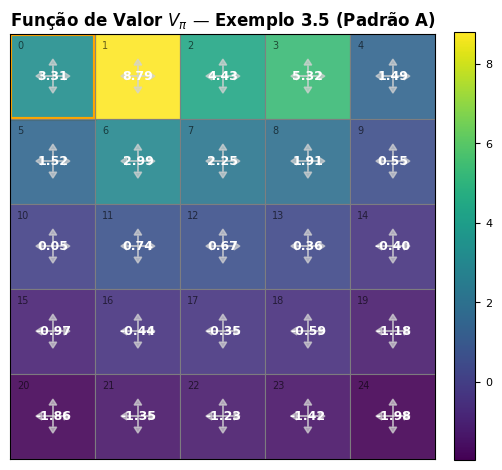

In [ ]:
vis = VisualizadorResultadoIndependente(
    P_dinamica=P_exemplo35,
    nlin=5, ncol=5, n_actions=n_actions,
    cmap_valores="viridis",
)

fig, ax = plt.subplots(figsize=(6, 6))
vis.desenhar(
    V=V_equi,
    politica=policy_equi,
    ax=ax,
    mostrar_setas=True,
    mostrar_valores=True,
    titulo=r"Função de Valor $V_{\pi}$ — Exemplo 3.5 (Padrão A)",
    mostrar_todas_acoes=True,
)
plt.show()